In [10]:
from langgraph.graph import START, END, StateGraph
from typing import TypedDict

In [11]:
class SpeedState(TypedDict):
    distance_km: float
    time_hours: float
    speed: float
    speed_level: str

In [12]:
def Calculate_Speed(state: SpeedState) -> SpeedState:
    distance = state['distance_km']
    time = state['time_hours']
    return {'speed': distance/time}

In [13]:
def Speed_Level(state: SpeedState)-> SpeedState:
    if state['speed'] >=5 and state['speed']<=10:
        return {'speed_level': 'low'}
    elif state['speed'] >10 and state['speed']<=20:
        return {'speed_level': 'normal'}
    elif state['speed'] >20 and state['speed']<=40:
        return {'speed_level': 'average'}
    elif state['speed'] >40 and state['speed']<=60:
        return {'speed_level': 'high'}
    else:
        return {'speed_level': 'very high'}

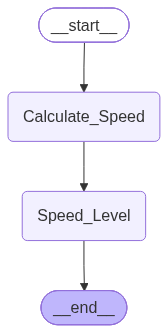

In [14]:
graph = StateGraph(SpeedState)
graph.add_node('Calculate_Speed', Calculate_Speed)
graph.add_node('Speed_Level', Speed_Level)
graph.add_edge(START, 'Calculate_Speed')
graph.add_edge('Calculate_Speed', 'Speed_Level')
graph.add_edge('Speed_Level', END)
workflow = graph.compile()
workflow

In [17]:
response = workflow.invoke({'distance_km': 75, 'time_hours': 1.5})
print(response)

{'distance_km': 75, 'time_hours': 1.5, 'speed': 50.0, 'speed_level': 'high'}
